# Phytoplankton size structure and fisheries catch
**Author:** Ryan Vandermeulen (NOAA Fisheries)</br>

## From tiny phytoplankton to big fish

Well, hello there, friend! Word on the street is that you want phytoplankton to add some context to your fisheries catch estimates. Well, you've come to the right place. In this notebook, we're going to explore how the size of phytoplankton influences the amount of energy that makes its way up the marine food web, and ultimately into fisheries catch. We'll start with a little chlorophyll-*a*, estimate the relative contributions of pico-, nano-, and microphytoplankton, and use those fractions to calculate an adjustment to trophic pathway length (ΔL). Then, we'll combine that information with primary production and fisheries catch data to see how well our predictions line up with actual catches. The best part? You can change a few parameters and see what happens. Let's do this!

## First, our libraries

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from pathlib import Path
import cartopy.crs as ccrs
import cartopy.feature as cfeature

## Let the partitioning begin!

Quite a gentleman IRL, Bob Brewin compiled some handy empirical relationships that allow us to estimate phytoplankton size structure from satellite-derived chlorophyll-*a* concentrations ([Brewin et al. 2011](https://doi.org/10.1364/AO.50.004535)). Using these relationships, we can estimate the relative (%) contributions of pico-, nano-, and microphytoplankton to total chlorophyll-*a*. The basic concept is as follows. Bob Brewin's size class model can be expressed through two simple exponential equations, such that the chlorophyll concentrations of the combined pico + nanophytoplankton population ($C_{p,n}$; cells <20 µm), and the picophytoplankton population ($C_{p}$; cells <2 µm), can be expressed as:

$C_{p,n} = C_{p,n}^m [1 - exp(-\dfrac {D_{p,n}}{C_{p,n}^m} C)] $

and

$C_{p} = C_{p}^m [1 - exp(-\dfrac {D_{p}}{C_{p}^m} C)] $

where $C$ is the total chlorophyll concentration from the satellite data, and $C_{p,n}^m$ and $C_{p}^m$ are constant asymptotic maximum values for the respective size class, and $D_{p,n}$ and $D_{p}$ (also constants) determine the fraction of total chlorophyll in the two size classes. Moving forward, through a simple difference, we can isolate the nanophytoplankton ($C_{n}; 2-20 µm$) by subtracting the above terms. 

$C_{n} = C_{p,n} - C_{p} $

and then, the microphytoplankton ($C_{m}$; >20 µm) as:

$C_{m} = C - C_{p,n} $

The fraction of each phytoplankton size class to total chlorophyll concentration ($f_p, f_n, f_m$) can then be calculated by dividing the size-specific chlorophyll concentration ($C_p, C_n, C_m$) by the total chlorophyll concentration ($C$) from satellite ocean color data. If your eyes are crossed, no worries, just be assured that someone spent a considerable amount of time figuring this all out, and now we can go with the maths :-) The constants below can be changed for different regions (see Table 4.2 in the [IOCCG report #15](https://ioccg.org/wp-content/uploads/2018/09/ioccg_report_15_2014.pdf)), but we're rolling with coefficients that are meant to work on global scales. 

![Is this clear?](https://raw.githubusercontent.com/fish-pace/2025-tutorials/main/Supporting_files/Princess_bride.gif)!

In [2]:
# Brewin (2011) size-class model coefficients
Cpm, Cpmn, Dp, Dpn = 0.13, 0.77, 0.80, 0.94

def size_fractions(chl):
    chl = np.asarray(chl, dtype=float)
    cp = Cpm * (1 - np.exp(-Dp * chl / Cpm))
    cpn = Cpmn * (1 - np.exp(-Dpn * chl / Cpmn))
    return cp / chl, (cpn - cp) / chl, (chl - cpn) / chl

## Some paramaterization for your consideration

We'll also set some bounds on a few constants used in Phyto2Fish. Feel free to play around with them! If you're a fish nerd, you may have very strong opinions about these particular parameters. Ultimately, it would be great if these values were as dynamic as the TL term, so perhaps you will be inspired to improve this framework.  

- α (the fraction of available production ultimately harvested by fisheries); we set this to 0.175 (as the average between 15-20%). 
- TE (trophic transfer efficiency); we set this to 0.13 (13%), where literatures values range from 6 - 20%
- wet weight (a somewhat hand-wavy conversion from carbon to fish wet weight. Fish are mostly water, after all)
>

In [3]:
# Fisheries model parameters
alpha, TE, wet_weight = 0.175, 0.13, 9

## Let's make a plot, y'all!

This will produce a close equivalent to Figure 1 in the manuscript. You may recall Equation 2:

$\Delta L = f_{micro}\omega_{micro} + f_{nano}\omega_{nano} + f_{pico}\omega_{pico}$

We're about to define these ω values below, and see how that impacts ΔL as a funciton of chlorophyll-a. Importantly, **these coefficients aren't meant to represent the literal number of trophic transfers associated with each phytoplankton size class**. Instead, they control the magnitude and shape of the relationship between chlorophyll-*a* and ΔL. Our configuration ($ω_{micro} = 0, ω_{nano} = 0.15, ω_{pico} = 2.5$) is such that ∆L approaches *one* additional trophic transfer under nanophytoplankton-dominated conditions and *two* additional trophic transfers under picophytoplankton-dominated conditions. Go ahead, twist those knobs and see what happens!

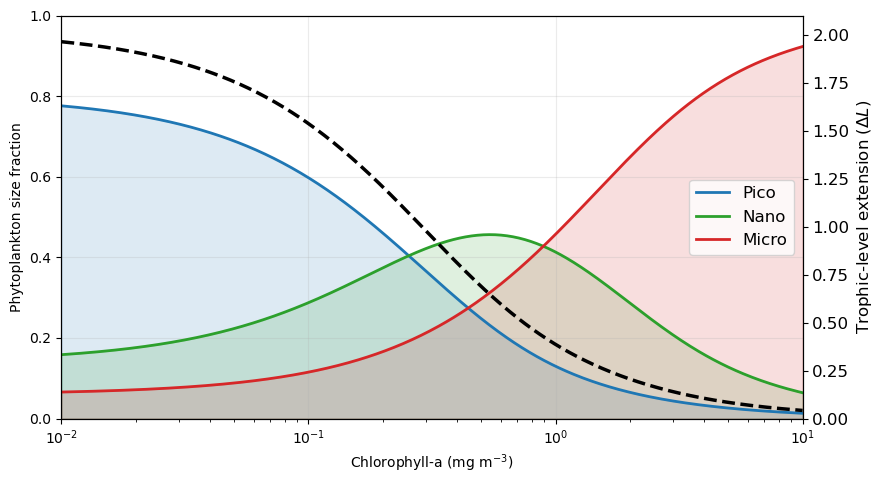

In [4]:
# Editable size-specific transfer weighting coefficients (pico, nano, micro)
omega_pico, omega_nano, omega_micro = 2.5, 0.15, 0.0

def delta_tl(chl):
    fp, fn, fm = size_fractions(chl)
    return fp * omega_pico + fn * omega_nano + fm * omega_micro

chl_range = np.logspace(-2, 1, 500)
fp, fn, fm = size_fractions(chl_range)
fig, ax = plt.subplots(figsize=(9, 5))
plt.rcParams.update({'font.size': 12})
for fraction, name, color in zip((fp, fn, fm), ('Pico', 'Nano', 'Micro'), ('tab:blue', 'tab:green', 'tab:red')):
    ax.plot(chl_range, fraction, label=name, color=color, lw=2)
    ax.fill_between(chl_range, fraction, color=color, alpha=0.15)
ax.set(xscale='log', xlabel='Chlorophyll-a (mg m$^{-3}$)', ylabel='Phytoplankton size fraction', ylim=(0, 1))
ax2 = ax.twinx()
ax2.plot(chl_range, delta_tl(chl_range), 'k--', lw=2.5, label=r'$\Delta L$')
ax2.set(ylabel=r'Trophic-level extension ($\Delta L$)', ylim=(0, 2.1))
ax.legend(loc='center right')
ax.set_xlim(0.01, 10)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Here is where the magic happens

I went back and forth about including all the data extraction and processing procedures in this notebook. I won't lie, some of it was a pain. Between manually downloading datasets, temporal interpolations, resampling, and wrangling files across different virtual computing environments (which apparently have the audacity of having a storage limit), there were quite a few moving parts. Perhaps most irritatingly, the Marine Ecoregions of the World (MEOWs) used by Sea Around Us occasionally have slightly different names than those in the original MEOW shapefile (that's what SAU_MEOW_lookup.csv helps reconcile).  

Ultimately, I decided to spare you the data-wrangling adventure and provide the processed datasets directly. All data were extracted and processed following the methods described in the manuscript, but I've left those steps out here to keep things approachable (and due to storage limitations). Below, we load up the extracted satellite NPP and chlorophyll-*a* data, the corresponding catch data + mean trophic levels from the Sea Around Us project, and then make sure our polygons and naming conventions play nice together. Then we calculate our predicted catch via Phyto2Fish using the parameterizations we defined above. 

Oh, another thing. See this line? 
>
> data = data[(data.Lat_Zone != 'Polar') & (data.NPP > 0) & (data.CHL > 0) & (data.Catch > 0) & data.TL.notna()].copy().
>
Comment that out if you want to include the polar regions in the analysis. Honestly, it didn't make a huge difference in the stats, but given the sparcity of satellite data and the assumptions we make about summing annual primary production, it made me quesy and uneasy, so we nixed it. 

Also, you'll notice that we read in annual mean SST values for each year and each MEOW. This wasn't used in the analysis, but hey, maybe you'll find something I didn't. Let's normalize making data accessible! 

In [6]:
# Read data
npp = pd.read_csv('Supporting_files/MEOW_integrated_NPP_1998_2025_tonnesC.csv')
chl = pd.read_csv('Supporting_files/MEOW_annual_OCCCI4km_mean_CHL_1998_2025.csv')
sst = pd.read_csv('Supporting_files/MEOW_annual_mean_SST_1998_2025.csv')
fishing_hours = pd.read_csv('Supporting_files/MEOW_mean_monthly_fishing_hours_2012_2024.csv')
catch = pd.read_csv('Supporting_files/MEOW_catch_smoothed_1998_present.csv')
tl = pd.read_csv('Supporting_files/MEOW_mtl_smoothed_1998_present.csv')
lookup = pd.read_csv('Supporting_files/SAU_MEOW_lookup.csv')
meow = gpd.read_file('Supporting_files/meow_ecos.shp')

# Translate SAU column names to MEOW ecoregion names.
rename = {f"MEOW_{r.meow_id}_{r.meow_name}".replace(' ', '_').replace('-', '_').replace('/', '_'): r.meow_name for r in lookup.itertuples()}
catch, tl = catch.rename(columns=rename), tl.rename(columns=rename)
common = sorted(set(npp) & set(chl) & set(catch) & set(tl) - {'year'})
print(f'Matched MEOWs: {len(common)}')

def to_long(df, value):
    return df[['year'] + common].melt('year', var_name='MEOW', value_name=value)
    
data = to_long(npp, 'NPP').merge(to_long(chl, 'CHL')).merge(to_long(catch, 'Catch')).merge(to_long(tl, 'TL'))
data = data.merge(fishing_hours[['MEOW', 'mean_monthly_fishing_hours']], on='MEOW', how='left')
zones = meow[['ECOREGION', 'Lat_Zone']].drop_duplicates().rename(columns={'ECOREGION': 'MEOW'})
data = data.merge(zones, on='MEOW', how='left')

# Exclude polar regions and invalid observations
data = data[(data.Lat_Zone != 'Polar') & (data.NPP > 0) & (data.CHL > 0) & (data.Catch > 0) & data.TL.notna()].copy()

# Phyto2Fish predictions
data['Delta_L'] = delta_tl(data.CHL)
data['Predicted'] = alpha * data.NPP * wet_weight * TE ** (data.TL - 1 + data.Delta_L)
data['Log_bias'] = np.log10(data.Predicted / data.Catch)
effort_data = data.dropna(subset=['mean_monthly_fishing_hours']).copy()

print(f'Valid ecoregion-years: {len(data)} | Years: {data.year.min()}–{data.year.max()}')
data.head()

Matched MEOWs: 206
Valid ecoregion-years: 4114 | Years: 1998–2019


,year,MEOW,NPP,CHL,Catch,TL,mean_monthly_fishing_hours,Lat_Zone,Delta_L,Predicted,Log_bias
0,1998,Adriatic Sea,1.467606e+07,0.648062,252279.4,3.390,98548.796011,Temperate,0.560098,56225.870202,-0.651946
1,1999,Adriatic Sea,1.380182e+07,0.589475,247520.2,3.376,98548.796011,Temperate,0.605009,49644.793556,-0.697737
2,2000,Adriatic Sea,1.359647e+07,0.635991,237026.8,3.372,98548.796011,Temperate,0.568820,53085.258233,-0.649824
3,2001,Adriatic Sea,1.366810e+07,0.643037,223398.6,3.378,98548.796011,Temperate,0.563697,53269.461960,-0.622602
4,2002,Adriatic Sea,1.481160e+07,0.931520,210637.8,3.392,98548.796011,Temperate,0.411120,76587.689293,-0.439377


## How'd we do? 

Because we scientists are gluttons for scatter plots, let's see how our predicted fisheries catch stacks up against the real thing! The dashed line represents a perfect match between observed and predicted catch. Points above the line indicate overprediction, while points below indicate underprediction. We've also included a few statistics to help quantify how well the model performs. Remember, we're trying to capture broad-scale patterns in fisheries production, not predict exactly how many fish will end up on someone's dinner plate. Obviously, there's a lot more going on in food web + fleet dynamics than bottom-up forcing from our phytoplankton overlords.

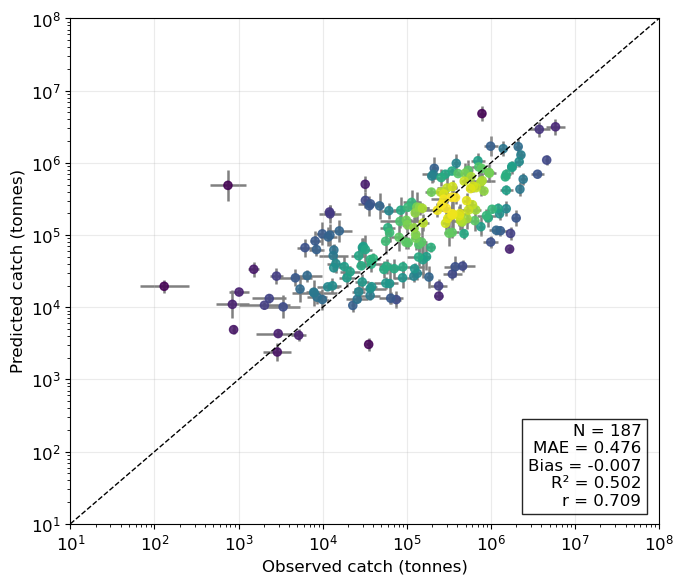

In [7]:
# Geometric mean ± 1 geometric standard deviation per MEOW
def geom_stats(x):
    log_x = np.log10(x)
    return pd.Series({'mean': 10**log_x.mean(), 'low': 10**(log_x.mean() - log_x.std()), 'high': 10**(log_x.mean() + log_x.std())})

avg = data.groupby('MEOW')[['Catch', 'Predicted']].apply(lambda g: pd.concat({var: geom_stats(g[var]) for var in ['Catch', 'Predicted']})).unstack()

x, y = avg[('Catch', 'mean')].to_numpy(), avg[('Predicted', 'mean')].to_numpy()
lx, ly = np.log10(x), np.log10(y)
error = ly - lx
mae, bias, r = np.mean(np.abs(error)), np.mean(error), np.corrcoef(lx, ly)[0, 1]
density = gaussian_kde(np.vstack([lx, ly]))(np.vstack([lx, ly]))
order = np.argsort(density)
xerr = [x - avg[('Catch', 'low')], avg[('Catch', 'high')] - x]
yerr = [y - avg[('Predicted', 'low')], avg[('Predicted', 'high')] - y]

fig, ax = plt.subplots(figsize=(7, 6))
ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', ecolor='0.5', lw=1.8, zorder=1)
ax.scatter(x[order], y[order], c=density[order], s=35, alpha=0.85, zorder=2)
ax.plot([1e1, 1e8], [1e1, 1e8], 'k--', lw=1)
ax.set(xscale='log', yscale='log', xlim=(1e1, 1e8), ylim=(1e1, 1e8), xlabel='Observed catch (tonnes)', ylabel='Predicted catch (tonnes)')
ax.text(0.97, 0.03, f'N = {len(x)}\nMAE = {mae:.3f}\nBias = {bias:.3f}\nR² = {r*r:.3f}\nr = {r:.3f}', transform=ax.transAxes, ha='right', va='bottom', bbox={'facecolor': 'white', 'alpha': 0.85})
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Mappy time!

Let's put all this in a little spatial context. This map shows the average difference between predicted and observed fisheries catch across the Marine Ecoregions of the World (MEOWs). Red regions indicate where our model overpredicts catch, while blue regions indicate underprediction. The closer to white, the better the agreement. Darker gray areas represent regions that were excluded from the analysis or lacked sufficient data, including regions for which fisheries catch data were unavailable from Sea Around Us (e.g., Antarctica).

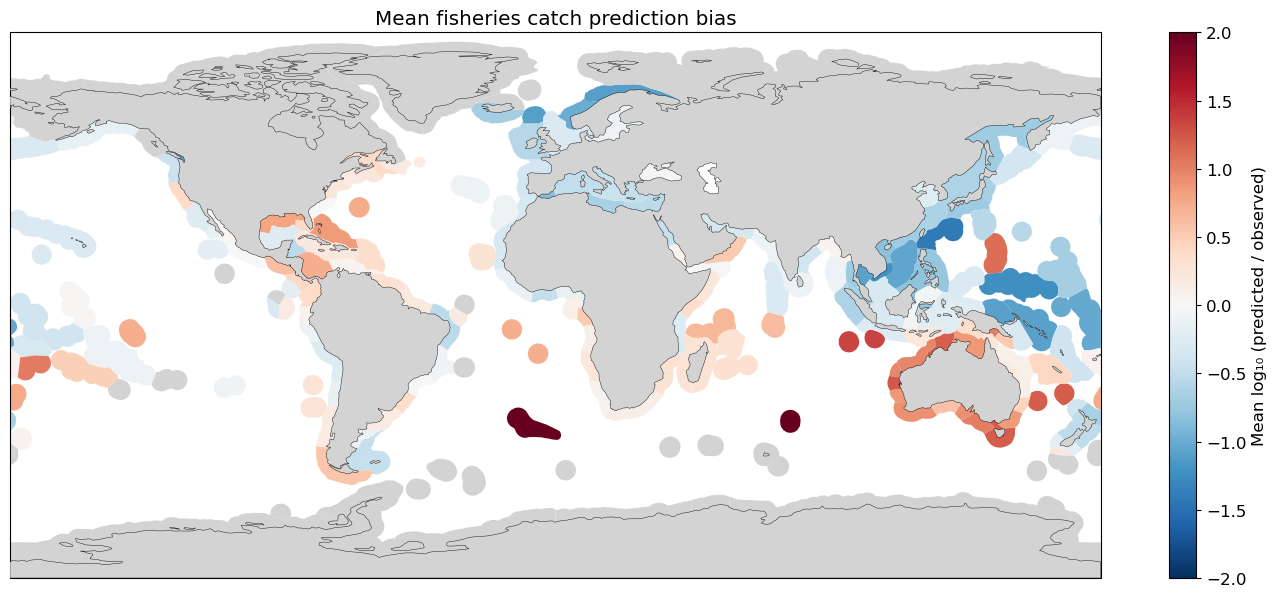

In [8]:
mean_bias = data.groupby('MEOW', as_index=False)['Log_bias'].mean()
map_data = meow.merge(mean_bias, left_on='ECOREGION', right_on='MEOW', how='left')

fig, ax = plt.subplots(figsize=(14, 6), subplot_kw={'projection': ccrs.PlateCarree()})
map_data.plot(column='Log_bias', ax=ax, cmap='RdBu_r', vmin=-2, vmax=2, legend=True, missing_kwds={'color': 'lightgray'}, legend_kwds={'label': 'Mean log₁₀ (predicted / observed)'})
ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.3, zorder=3)
ax.set(xlabel='Longitude', ylabel='Latitude', title='Mean fisheries catch prediction bias')
plt.tight_layout()
plt.show()

## Exploring marine ecosystems around the world

You want to make an interactive dashboard? Let's explore individual marine ecoregions and see how their environmental conditions, phytoplankton communities, and fisheries compare. As a reminder, we're using **Marine Ecoregions of the World (MEOW)**, which divide the world's coastal oceans into geographically distinct ecological regions. Select an ecoregion from the dropdown menu, and the dashboard will summarize nine indicators, from sea surface temperature and primary production to observed and predicted fisheries catch. The accompanying map provides a little geographic context. You can change which variable is displayed and zoom in or out to explore neighboring ecosystems. A few things to know before diving in:

- **Environmental conditions:** Sea surface temperature and chlorophyll-*a* are shown as trends per decade over 1998–2025. The other annual indicators are summarized as their mean ± standard deviation over the available model period (1998–2019). Arrows indicate statistically significant increases or decreases (p < 0.05).
- **Fisheries catch:** We're comparing observed catches with two mechanistic estimates. The baseline model uses primary production and the catch-weighted mean trophic level, while the size-adjusted model (Phyto2Fish) also accounts for the additional trophic transfers associated with smaller phytoplankton.
- **Fishing activity:** Apparent fishing effort comes from Global Fishing Watch satellite-based vessel tracking. We summarize average monthly fishing hours over 2012–2024 and show where each ecoregion falls relative to others worldwide. Keep in mind that these are total hours, not fishing intensity per unit area.

>

*One important caveat:* These model estimates aren't forecasts of future catch, nor are they recommendations for how much fish should be harvested. Instead, the idea is to explore how differences in primary production, phytoplankton size structure, and trophic pathways might help explain why some marine ecosystems support more fisheries catch than others. So go ahead, pick somewhere interesting. Does the model perform better in productive coastal waters or in regions dominated by smaller phytoplankton? Do changes in phytoplankton communities correspond with changes in predicted fisheries production? And where does the model seem to miss something important? 



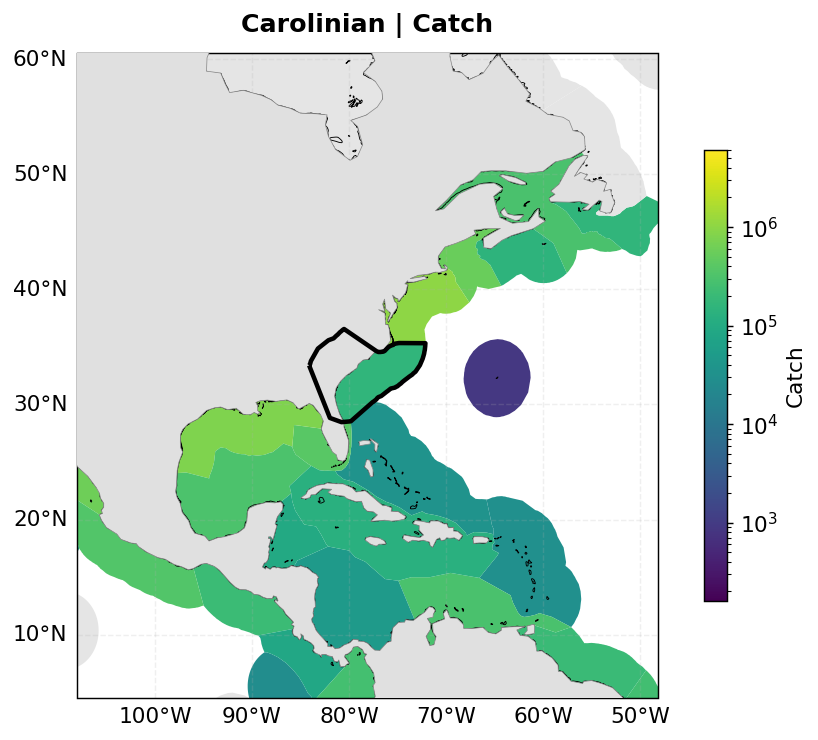

In [9]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import ecosystem_dashboard as dash
import ecosystem_viewer as viewer

dash.configure(data=data, sst=sst, chl=chl, meow=meow, alpha=alpha, TE=TE, wet_weight=wet_weight)
viewer.launch(region_name='Carolinian', map_variable='Catch', zoom=2.00);

## Wrapping things up

Well, there you have it! We've gone from tiny phytoplankton to fisheries catch, with a little satellite oceanography and trophic ecology along the way. The size structure of phytoplankton communities can influence how efficiently energy moves through the food web, and ultimately how much of that energy becomes available to support fisheries production. By accounting for those differences in trophic pathways, we can improve upon traditional approaches that rely on primary production and trophic level alone. Of course, marine ecosystems are considerably more complicated than our little model suggests. Fisheries catches reflect fishing activity, management decisions, species composition, and a whole host of ecological processes that we haven't explicitly considered. Our estimates aren't intended to predict exactly how many fish will be caught, much less prescribe how many *should* be caught.

But that's part of the fun of exploring these relationships. A relatively simple framework can help us ask interesting questions about why fisheries production differs among ecosystems, how changing phytoplankton communities might influence food-web dynamics, and where our understanding still has room to grow. Much of the information we've explored comes from satellites orbiting hundreds of kilometers above the ocean. While we can't directly see fish, follow every trophic interaction, or measure every ecosystem process from space, we can observe some of the fundamental conditions that help shape marine food webs.  **And there's still plenty to discover about how those conditions influence the ecosystems and fisheries that depend on them.**

Thanks for coming along for the ride!